[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


Decision Tree Metrics:
F1 Score: 0.64
Recall: 0.64
Accuracy: 0.65
Precision: 0.64
Confusion Matrix:
[[734 394]
 [389 703]]

Random Forest Metrics:
F1 Score: 0.69
Recall: 0.63
Accuracy: 0.72
Precision: 0.76
Confusion Matrix:
[[912 216]
 [399 693]]

Gradient Boosting Metrics:
F1 Score: 0.69
Recall: 0.64
Accuracy: 0.72
Precision: 0.76
Confusion Matrix:
[[908 220]
 [394 698]]

SVM Metrics:
F1 Score: 0.72
Recall: 0.68
Accuracy: 0.74
Precision: 0.77
Confusion Matrix:
[[899 229]
 [346 746]]

K-Nearest Neighbors Metrics:
F1 Score: 0.25
Recall: 0.15
Accuracy: 0.56
Precision: 0.80
Confusion Matrix:
[[1088   40]
 [ 930  162]]

Naive Bayes Metrics:
F1 Score: 0.69
Recall: 0.67
Accuracy: 0.71
Precision: 0.72
Confusion Matrix:
[[839 289]
 [359 733]]

Logistic Regression Metrics:
F1 Score: 0.72
Recall: 0.69
Accuracy: 0.73
Precision: 0.74
Confusion Matrix:
[[868 260]
 [336 756]]



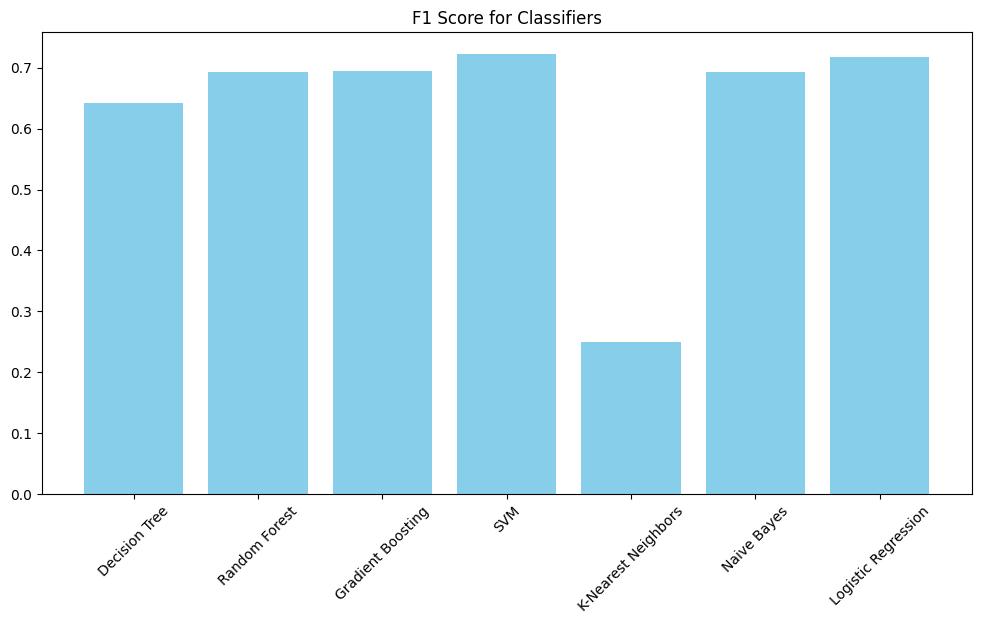

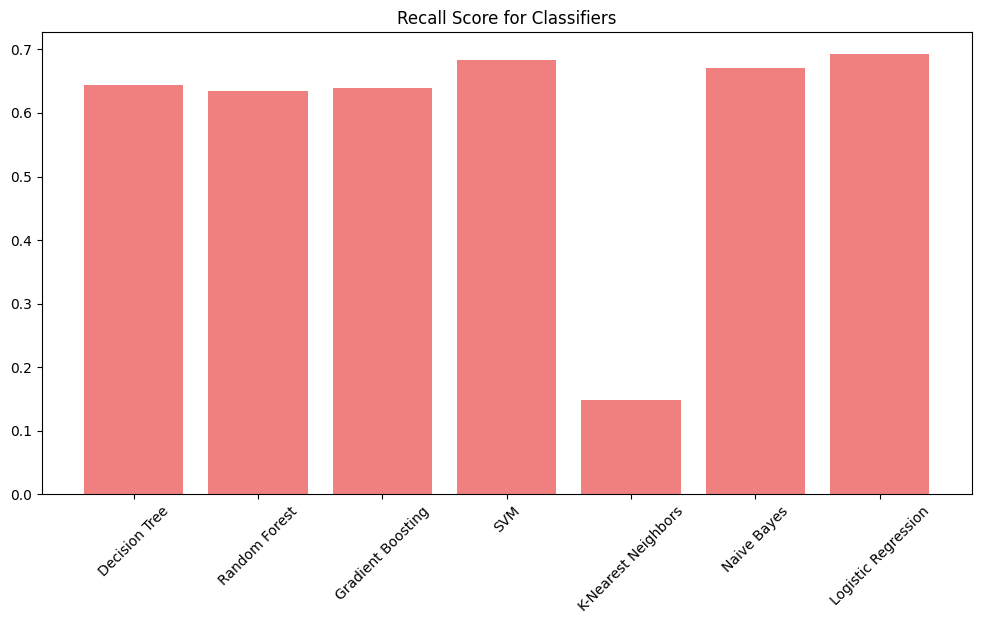

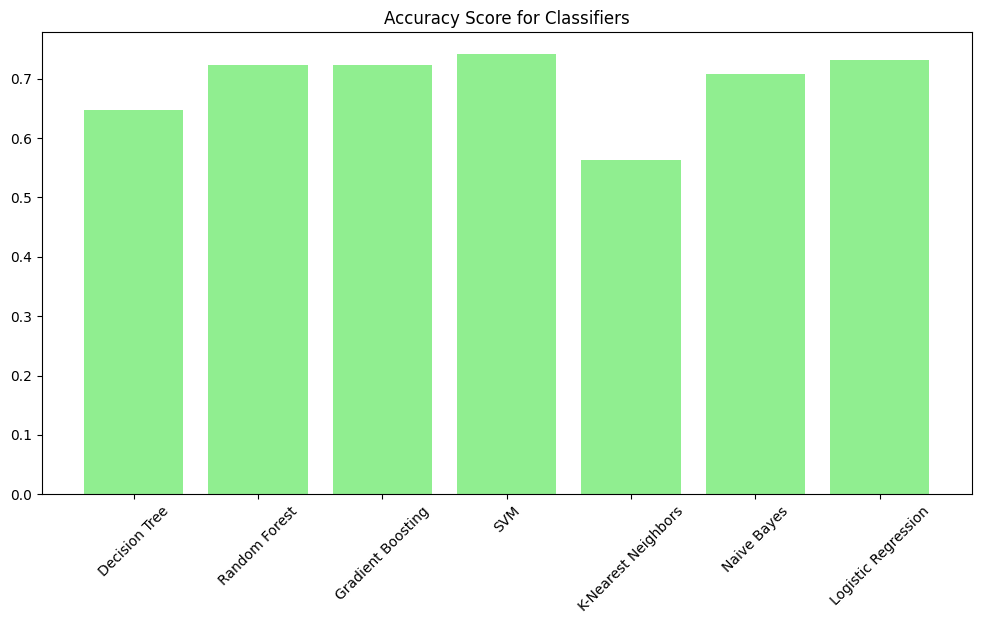

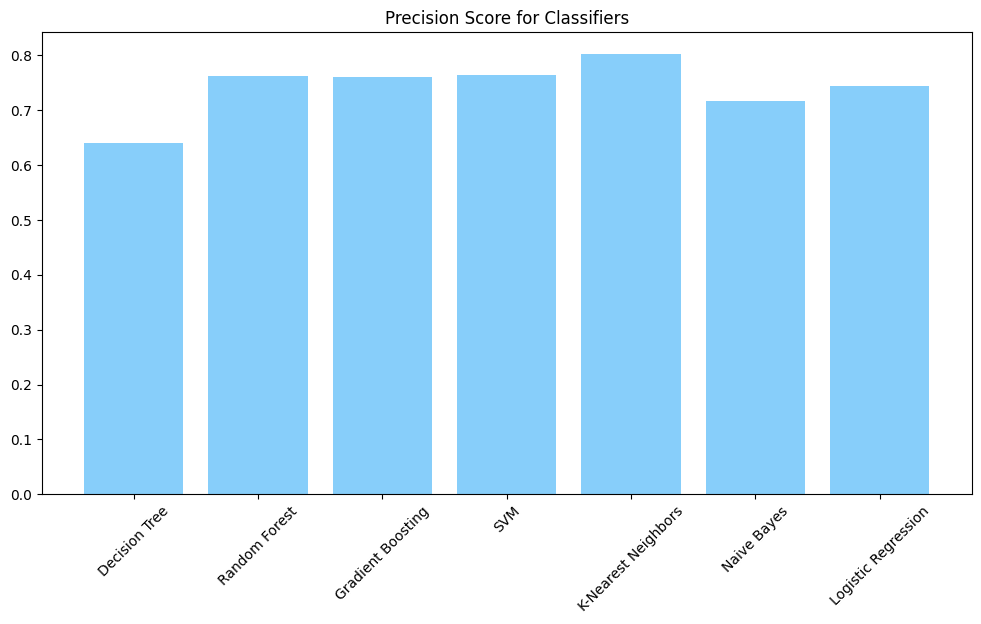

Best Classifier in Terms of Accuracy: SVM


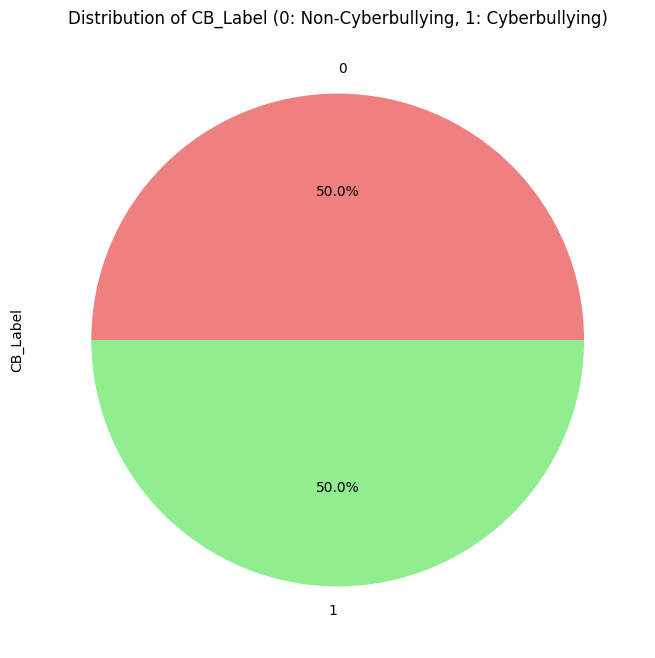

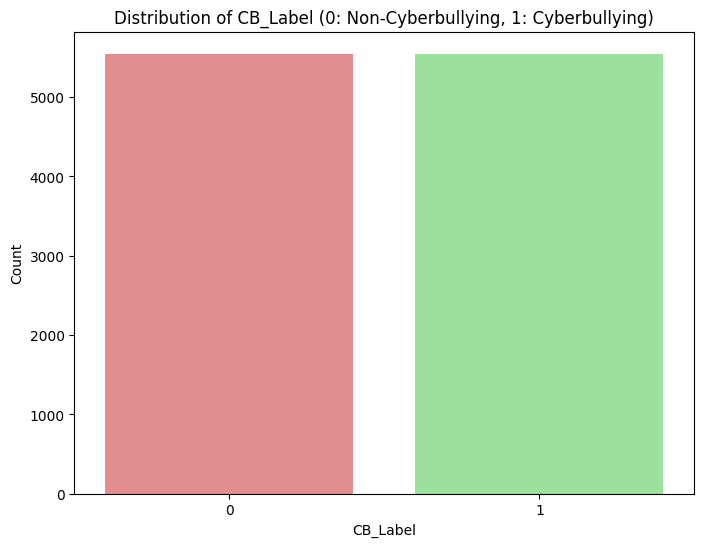

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, recall_score, accuracy_score, precision_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

# Load your cyberbullying comments dataset (replace 'your_dataset.csv' with your actual dataset path)
data = pd.read_csv('/content/sample_data/CyberBullying Comments Dataset.csv')

# Preprocessing
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    words = nltk.word_tokenize(text)
    stop_words = set(stopwords.words('english'))
    words = [word for word in words if word not in stop_words]
    stemmer = PorterStemmer()
    words = [stemmer.stem(word) for word in words]
    lemmatizer = WordNetLemmatizer()
    words = [lemmatizer.lemmatize(word) for word in words]
    cleaned_text = ' '.join(words)
    return cleaned_text

data['Text'] = data['Text'].apply(preprocess_text)

# Split data into features (X) and target (y)
X = data['Text']
y = data['CB_Label']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Vectorize text data using TF-IDF
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Initialize classifiers with hyperparameter tuning
classifiers = {
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Gradient Boosting': GradientBoostingClassifier(),
    'SVM': SVC(),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression()
}

# Define hyperparameters for grid search
param_grid = {
    'Random Forest': {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20]},
    'Gradient Boosting': {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.1, 0.2]},
    'SVM': {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},
    # Add hyperparameters for other classifiers
}

results = {}

# Perform hyperparameter tuning for each classifier
for name, clf in classifiers.items():
    if name in param_grid:
        grid_search = GridSearchCV(clf, param_grid[name], cv=5, n_jobs=-1)
        grid_search.fit(X_train_tfidf, y_train)
        best_classifier = grid_search.best_estimator_
    else:
        best_classifier = clf

    best_classifier.fit(X_train_tfidf, y_train)
    y_pred = best_classifier.predict(X_test_tfidf)

    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    confusion = confusion_matrix(y_test, y_pred)

    results[name] = {
        'F1 Score': f1,
        'Recall': recall,
        'Accuracy': accuracy,
        'Precision': precision,
        'Confusion Matrix': confusion
    }

# Display evaluation metrics
for name, metrics in results.items():
    print(f'{name} Metrics:')
    print(f'F1 Score: {metrics["F1 Score"]:.2f}')
    print(f'Recall: {metrics["Recall"]:.2f}')
    print(f'Accuracy: {metrics["Accuracy"]:.2f}')
    print(f'Precision: {metrics["Precision"]:.2f}')
    print(f'Confusion Matrix:\n{metrics["Confusion Matrix"]}')
    print()

# Plot results
f1_scores = [metrics['F1 Score'] for metrics in results.values()]
recall_scores = [metrics['Recall'] for metrics in results.values()]
accuracy_scores = [metrics['Accuracy'] for metrics in results.values()]
precision_scores = [metrics['Precision'] for metrics in results.values()]

plt.figure(figsize=(12, 6))
plt.bar(classifiers.keys(), f1_scores, color='skyblue')
plt.title('F1 Score for Classifiers')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 6))
plt.bar(classifiers.keys(), recall_scores, color='lightcoral')
plt.title('Recall Score for Classifiers')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 6))
plt.bar(classifiers.keys(), accuracy_scores, color='lightgreen')
plt.title('Accuracy Score for Classifiers')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 6))
plt.bar(classifiers.keys(), precision_scores, color='lightskyblue')
plt.title('Precision Score for Classifiers')
plt.xticks(rotation=45)
plt.show()

# Find the best classifier based on accuracy
best_classifier = max(results, key=lambda k: results[k]['Accuracy'])
print(f'Best Classifier in Terms of Accuracy: {best_classifier}')

# Visualization of CB_Label distribution
plt.figure(figsize=(8, 8))
data['CB_Label'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['lightcoral', 'lightgreen'])
plt.title('Distribution of CB_Label (0: Non-Cyberbullying, 1: Cyberbullying)')
plt.show()

# Bar graph for CB_Label distribution
plt.figure(figsize=(8, 6))
sns.countplot(data=data, x='CB_Label', palette=['lightcoral', 'lightgreen'])
plt.title('Distribution of CB_Label (0: Non-Cyberbullying, 1: Cyberbullying)')
plt.xlabel('CB_Label')
plt.ylabel('Count')
plt.show()
